<a href="https://colab.research.google.com/github/DanialNayyar/Retail-Operations-Statistical-Analysis/blob/main/Retail_Operations_%26_Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question: Do UK and international customers exhibit significant differences in their purchasing behaviour. What can retailers learn from these differences


In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
X = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)


{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [4]:
X.head()

,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
X.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


In [7]:
X.isna().sum()

,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [8]:
X.shape

(541909, 6)

In [9]:
X.nunique()

,0
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [10]:
X["Description"].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2369
REGENCY CAKESTAND 3 TIER,2200
JUMBO BAG RED RETROSPOT,2159
PARTY BUNTING,1727
LUNCH BAG RED RETROSPOT,1638
...,...
ANT SILVER TURQUOISE BOUDICCA RING,1
Damages,1
Found by jackie,1


In [11]:
X["Quantity"].value_counts()

,count
Quantity,
1,148227
2,81829
12,61063
6,40868
4,38484
...,...
-355,1
-155,1
1404,1


In [12]:
X["InvoiceDate"].value_counts()

,count
InvoiceDate,
10/31/2011 14:41,1114
12/8/2011 9:28,749
12/9/2011 10:03,731
12/5/2011 17:24,721
6/29/2011 15:58,705
...,...
10/27/2011 10:58,1
10/27/2011 12:57,1
10/27/2011 12:13,1


In [13]:
X["UnitPrice"].value_counts()

,count
UnitPrice,
1.25,50496
1.65,38181
0.85,28497
2.95,27768
0.42,24533
...,...
185.28,1
187.21,1
252.57,1


In [14]:
X["CustomerID"].value_counts()

,count
CustomerID,
17841.0,7983
14911.0,5903
14096.0,5128
12748.0,4642
14606.0,2782
...,...
17986.0,1
13256.0,1
18184.0,1


In [15]:
X["Country"].value_counts()

,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


In [16]:
###delete this cell after
X.isna().sum()


,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


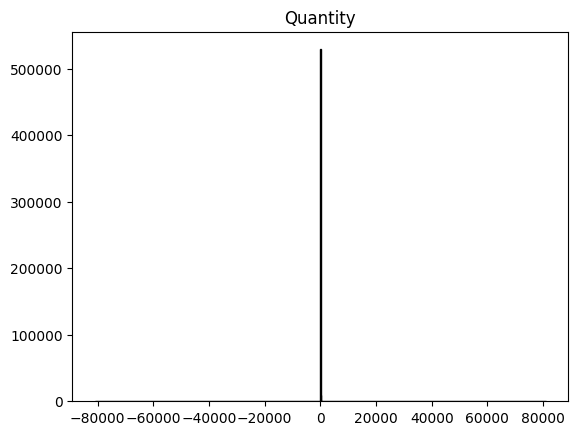

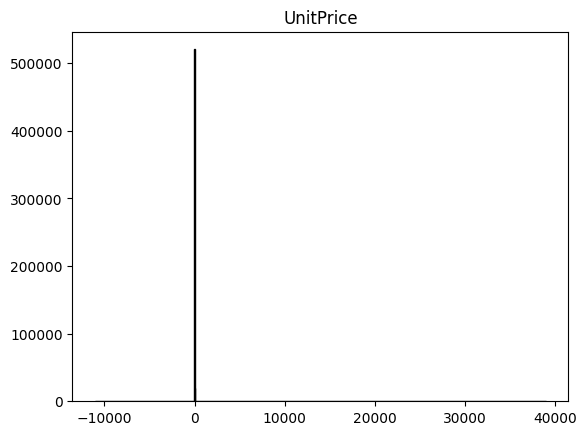

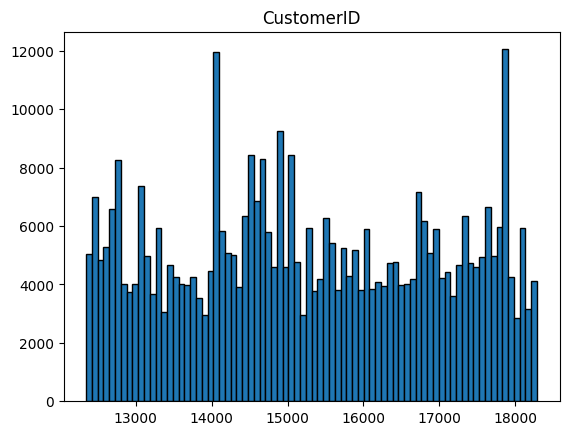

In [17]:
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

### Freedman-Diaconis rule for bins size
q25 = np.percentile(X[num_cols], 25)
q75 = np.percentile(X[num_cols], 75)
iqr = q75 - q25

bin_width = 2*iqr/(len(X)**(1/3))

if bin_width > 0:
  bins = int(np.ciel((X.max()-X.min())//bin_width))
  for col in num_cols:
    plt.title(col)
    plt.hist(X[col], edgecolor = "black",linestyle="solid", bins = bins)
    plt.show()
else:
  bins = "auto" #auto if there is a division by 0
  for col in num_cols:
    plt.title(col)
    plt.hist(X[col], edgecolor = "black",linestyle="solid", bins = bins)
    plt.show()

From a quick and brief look at the data and its features (count, missing vals, distribution etc) there are a nearlyt 1500 missing values in the "Description" series and over 135,080 missing values in the "CustomerID" sereies. Other features dont have any missing values.

Based on the UCI webpage, the "Description" feature is just the product name, as such it probably wont have much significance in the overall analysis.

"CustomerID" however, is a 5 digit number that is uniquely assigned to each customer. Having over 135,000 missing values out of the total nearly 541,000 will pose a significant challenge in the overall analysis as it will have to be dealt with appropriately. Missing "CustomerID" means that it would be difficult to assign orders to region (i.e. UK and Non UK) which would make the research to answer the project question more challenging.




In [18]:
print(f"Quantity below 0: {len(X[X['Quantity']<0])}")
print(f"UnitPrice below 0: {len(X[X['UnitPrice']<0])}")
print(f"UnitPrice equal to 0: {(X["UnitPrice"]==0).sum()}")


Quantity below 0: 10624
UnitPrice below 0: 2
UnitPrice equal to 0: 2515


In [19]:
X.sort_values(by = ["Quantity"],ascending = False)

,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,"PAPER CRAFT , LITTLE BIRDIE",80995,12/9/2011 9:15,2.08,16446.0,United Kingdom
61619,MEDIUM CERAMIC TOP STORAGE JAR,74215,1/18/2011 10:01,1.04,12346.0,United Kingdom
502122,ASSTD DESIGN 3D PAPER STICKERS,12540,11/25/2011 15:57,0.00,13256.0,United Kingdom
74614,NaN,5568,1/28/2011 12:03,0.00,NaN,United Kingdom
421632,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,10/27/2011 12:26,0.21,12901.0,United Kingdom
...,...,...,...,...,...,...
4287,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,12/2/2010 14:23,0.03,15838.0,United Kingdom
225530,printing smudges/thrown away,-9600,6/14/2011 10:37,0.00,NaN,United Kingdom
225529,printing smudges/thrown away,-9600,6/14/2011 10:37,0.00,NaN,United Kingdom
61624,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/2011 10:17,1.04,12346.0,United Kingdom


In [20]:
invoice_no = online_retail.data.ids['InvoiceNo']
invoice_no = pd.DataFrame(invoice_no)

In [21]:
stock_code = online_retail.data.ids['StockCode']
stock_code = pd.DataFrame(stock_code)

In [22]:
print(invoice_no)

       InvoiceNo
0         536365
1         536365
2         536365
3         536365
4         536365
...          ...
541904    581587
541905    581587
541906    581587
541907    581587
541908    581587

[541909 rows x 1 columns]


In [23]:
print(stock_code)

       StockCode
0         85123A
1          71053
2         84406B
3         84029G
4         84029E
...          ...
541904     22613
541905     22899
541906     23254
541907     23255
541908     22138

[541909 rows x 1 columns]


In [24]:
df = pd.concat([invoice_no, stock_code], axis=1)

In [25]:
df = pd.concat([df, X], axis=1)

In [26]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


According to the UCI website, if the invoice number starts with a "C" it represents a cancellation

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [28]:
df.shape

(541909, 8)

In [29]:
print(f"Number of rows that begin with a 'C' {df["InvoiceNo"].str.startswith("C").sum()}") #potential cancellations

Number of rows that begin with a 'C' 9288


In [30]:
df.loc[df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] < 0)].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [31]:
print(f"Number of rows that begin with a 'C' and have a negative quantity is: {df.loc[df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] < 0)].shape[0]}")

Number of rows that begin with a 'C' and have a negative quantity is: 9288


In [32]:
print(f"Number of rows that begin with a 'C' and have a positive quantity is: {df.loc[df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] > 0)].shape[0]}")

Number of rows that begin with a 'C' and have a positive quantity is: 0


In [33]:
df.loc[~df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] < 0)].shape[0]

#~ negates boolean condition

1336

In [34]:
df.loc[~df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] < 0)].head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,12/2/2010 14:42,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,12/3/2010 15:30,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,12/3/2010 15:32,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,12/3/2010 15:33,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,12/3/2010 15:33,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,12/3/2010 15:34,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,12/3/2010 15:35,0.0,NaN,United Kingdom


In [35]:
no_c_negative = df.loc[
    (~df["InvoiceNo"].str.startswith("C", na=False))
    & (df["Quantity"] < 0)
]

In [36]:
no_c_negative.shape

(1336, 8)

In [37]:
no_c_negative["CustomerID"].isna().sum()

np.int64(1336)

In [38]:
(no_c_negative["UnitPrice"]==0).sum()

np.int64(1336)

In [39]:
(no_c_negative["UnitPrice"]<0).sum()

np.int64(0)

In [40]:
(no_c_negative["UnitPrice"]>0).sum()

np.int64(0)

In [41]:
(no_c_negative["Description"].isna()).sum()

np.int64(862)

In [42]:
sales_df = df.loc[
    (df["Quantity"]>0)
    & (df["UnitPrice"]>0)
    & (~df["Description"].str.startswith("C", na=False))
].copy()

In [43]:
sales_df["Revenue"] = sales_df["Quantity"]*sales_df["UnitPrice"]

In [44]:
sales_df.shape

(486607, 9)

In [45]:
sales_df["Revenue"].describe()

,Revenue
count,486607.000000
mean,20.271352
std,281.722730
min,0.001000
25%,3.750000
50%,9.920000
75%,17.700000
max,168469.600000


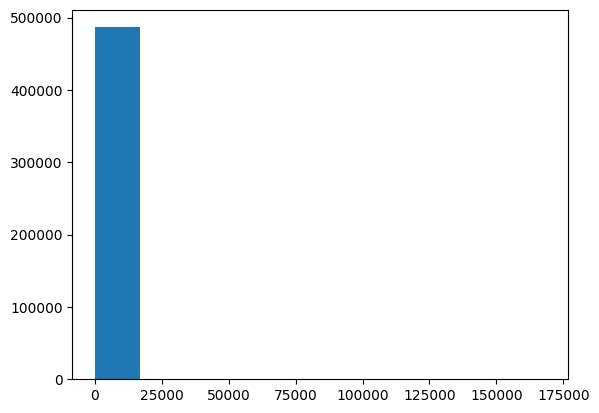

In [46]:
plt.hist(sales_df["Revenue"])
plt.show()

In [47]:
sales_df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,120409
Country,0
Revenue,0


# SQL

In [48]:
import sqlite3

In [49]:
connection = sqlite3.connect("retail_operations_statistical_analysis.db")

In [50]:
sales_df.to_sql(name = "sales",
                con = connection,
                if_exists = "replace",
                index = False)

486607

In [51]:
#check
query = """
SELECT COUNT(*)
FROM sales

"""

pd.read_sql_query(query, connection)

,COUNT(*)
0,486607


In [52]:

query = """
SELECT Country,
  SUM(Revenue) AS Total_Revenue
FROM sales
  GROUP BY Country
  ORDER BY Total_Revenue DESC
  LIMIT 10
"""

pd.read_sql_query(query, connection)

,Country,Total_Revenue
0,United Kingdom,8355136.324
1,Netherlands,260582.780
2,EIRE,258394.570
3,Germany,213862.350
4,France,192822.900
5,Australia,131875.540
6,Switzerland,52486.680
7,Spain,51805.880
8,Belgium,37835.170
9,Sweden,37775.210


In [53]:
query = """
SELECT InvoiceNo, Country,
  SUM(Revenue) AS OrderValue
FROM sales
  GROUP BY InvoiceNo, Country
  ORDER BY OrderValue DESC
  LIMIT 10
"""

pd.read_sql_query(query, connection)



,InvoiceNo,Country,OrderValue
0,581483,United Kingdom,168469.60
1,541431,United Kingdom,77183.60
2,574941,United Kingdom,52595.79
3,576365,United Kingdom,48819.81
4,556444,United Kingdom,38970.00
5,567423,United Kingdom,31698.16
6,572209,United Kingdom,22206.00
7,567381,United Kingdom,22104.80
8,563614,Australia,21880.44
9,550461,United Kingdom,21535.90


In [54]:
query = """
WITH InvoiceTotals AS (
SELECT InvoiceNo, Country,
  SUM(Revenue) AS OrderValue
FROM sales
  GROUP BY InvoiceNo, Country
  )

SELECT *
FROM InvoiceTotals
ORDER BY OrderValue DESC
LIMIT 10;
"""


pd.read_sql_query(query, connection)



,InvoiceNo,Country,OrderValue
0,581483,United Kingdom,168469.60
1,541431,United Kingdom,77183.60
2,574941,United Kingdom,52595.79
3,576365,United Kingdom,48819.81
4,556444,United Kingdom,38970.00
5,567423,United Kingdom,31698.16
6,572209,United Kingdom,22206.00
7,567381,United Kingdom,22104.80
8,563614,Australia,21880.44
9,550461,United Kingdom,21535.90


In [55]:
query = """
WITH InvoiceTotals AS (
SELECT InvoiceNo, Country,
  SUM(Revenue) AS OrderValue
FROM sales
  GROUP BY InvoiceNo, Country
  ),

RegionalOrders AS (
SELECT InvoiceNo, OrderValue,

CASE
  WHEN Country = "United Kingdom" THEN "UK"
  ELSE "International"
END AS Region
FROM InvoiceTotals
)


SELECT Region, COUNT(*) AS NumberOfOrder, AVG(OrderValue) AS AvgOrderValue
FROM RegionalOrders
GROUP BY Region
ORDER BY AvgOrderValue DESC


"""
pd.read_sql_query(query, connection)

,Region,NumberOfOrder,AvgOrderValue
0,International,1931,781.483925
1,UK,17866,467.655677


In [56]:
query = """
WITH InvoiceTotals AS (
SELECT InvoiceNo, Country,
  SUM(Revenue) AS OrderValue
FROM sales
  GROUP BY InvoiceNo, Country
  ),

RegionalOrders AS (
SELECT InvoiceNo, OrderValue,

CASE
  WHEN Country = "United Kingdom" THEN "UK"
  ELSE "International"
END AS Region
FROM InvoiceTotals
)


SELECT Region, OrderValue
FROM RegionalOrders;



"""
pd.read_sql_query(query, connection)

,Region,OrderValue
0,UK,117.12
1,UK,22.20
2,UK,278.73
3,UK,70.05
4,UK,17.85
...,...,...
19792,UK,140.64
19793,UK,329.05
19794,UK,339.20
19795,International,148.05


In [57]:
regional_orders = pd.read_sql_query(query, connection)

In [58]:
summary = regional_orders.groupby("Region").agg(["count", "mean", "median", "std"])

In [59]:
summary

OrderValue                                  
                   count        mean   median          std
Region                                                    
International       1931  781.483925  389.620  1626.678428
UK                 17866  467.655677  268.665  1757.097456

In [60]:
summary["Standard Error of Mean"] = summary[("OrderValue", "std")] / np.sqrt(summary[("OrderValue", "count")])

In [61]:
summary

OrderValue                                    \
                   count        mean   median          std   
Region                                                       
International       1931  781.483925  389.620  1626.678428   
UK                 17866  467.655677  268.665  1757.097456   

              Standard Error of Mean  
                                      
Region                                
International              37.017797  
UK                         13.145654

In [62]:
summary["Confidence Interval Upper"] = summary[("OrderValue", "mean")] + 1.96 * summary["Standard Error of Mean"]
summary["Confidence Interval Lower"] = summary[("OrderValue", "mean")] - 1.96 * summary["Standard Error of Mean"]

In [63]:
summary["CI Difference"] = summary["Confidence Interval Upper"] - summary["Confidence Interval Lower"]


In [64]:
summary

OrderValue                                    \
                   count        mean   median          std   
Region                                                       
International       1931  781.483925  389.620  1626.678428   
UK                 17866  467.655677  268.665  1757.097456   

              Standard Error of Mean Confidence Interval Upper  \
                                                                 
Region                                                           
International              37.017797                854.038808   
UK                         13.145654                493.421158   

              Confidence Interval Lower CI Difference  
                                                       
Region                                                 
International                708.929043    145.109765  
UK                           441.890196     51.530962

In [65]:
uk_orders = regional_orders.loc[regional_orders["Region"]=="UK", "OrderValue"]
international_orders = regional_orders.loc[regional_orders["Region"]=="International", "OrderValue"]

print(len(uk_orders))
print(len(international_orders))

17866
1931


In [66]:
from scipy.stats import ttest_ind
#pval = 0.05

ttest_ind(uk_orders, international_orders, equal_var=False)


TtestResult(statistic=np.float64(-7.988981354468438), pvalue=np.float64(2.075914900962049e-15), df=np.float64(2443.2731426945475))

In [67]:
summary["Mean Difference"] = summary[("OrderValue", "mean")]["International"] - summary[("OrderValue", "mean")]["UK"]

In [68]:
summary["SE Difference"] = np.sqrt((summary["Standard Error of Mean"]["International"])**2 + (summary["Standard Error of Mean"]["UK"])**2)

In [69]:
summary["95% CI Upper"] = summary["Mean Difference"] + 1.96 * summary["SE Difference"]
summary["95% CI Lower"] = summary["Mean Difference"] - 1.96 * summary["SE Difference"]

In [70]:
summary

OrderValue                                    \
                   count        mean   median          std   
Region                                                       
International       1931  781.483925  389.620  1626.678428   
UK                 17866  467.655677  268.665  1757.097456   

              Standard Error of Mean Confidence Interval Upper  \
                                                                 
Region                                                           
International              37.017797                854.038808   
UK                         13.145654                493.421158   

              Confidence Interval Lower CI Difference Mean Difference  \
                                                                        
Region                                                                  
International                708.929043    145.109765      313.828248   
UK                           441.890196     51.530962      313.828248   

              SE Difference 95% CI Upper 95% CI Lower  
                                                       
Region                                                 
International     39.282636   390.822216   236.834281  
UK                39.282636   390.822216   236.834281

In [71]:
regional_orders.groupby("Region")["OrderValue"].quantile([0.95,0.99])

Region             
International  0.95    2540.5800
               0.99    8602.4880
UK             0.95    1383.5100
               0.99    4064.9605
Name: OrderValue, dtype: float64

In [72]:
thresholds = regional_orders.groupby("Region")["OrderValue"].quantile(0.99)

In [73]:
thresholds

,OrderValue
Region,
International,8602.4880
UK,4064.9605


In [74]:
mapped_thresholds = regional_orders['Region'].map(thresholds)
trimmed_orderes_99 = regional_orders[regional_orders["OrderValue"] <= mapped_thresholds]

In [75]:
trimmed_orderes_99.groupby("Region")["OrderValue"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Region,,,,
International,1911,647.518676,385.14,892.587642
UK,17687,380.203948,265.65,456.785109


In [76]:
uk_orders_trimmed = trimmed_orderes_99.loc[trimmed_orderes_99["Region"]=="UK", "OrderValue"]
international_orders_trimmed = trimmed_orderes_99.loc[trimmed_orderes_99["Region"]=="International", "OrderValue"]

In [77]:
ttest_ind(uk_orders_trimmed, international_orders_trimmed, equal_var=False)


TtestResult(statistic=np.float64(-12.910505267231478), pvalue=np.float64(1.0654568454667044e-36), df=np.float64(2019.4462892843715))

In [78]:
original_mean_int = summary[("OrderValue", "mean")]["International"]
original_mean_uk = summary[("OrderValue", "mean")]["UK"]


trimmed_mean_int = trimmed_orderes_99.loc[trimmed_orderes_99["Region"]=="International", "OrderValue"].mean()
trimmed_mean_uk = trimmed_orderes_99.loc[trimmed_orderes_99["Region"]=="UK", "OrderValue"].mean()

percent_reduction_int = 100 *(original_mean_int - trimmed_mean_int)/original_mean_int
percent_reduction_uk = 100 * (original_mean_uk - trimmed_mean_uk)/original_mean_uk

print(f"% Reduction in Mean OrderValue for International Orders: {percent_reduction_int}")
print(f"% Reduction in Mean OrderValue for UK Orders: {percent_reduction_uk}")

% Reduction in Mean OrderValue for International Orders: 17.142419054644233
% Reduction in Mean OrderValue for UK Orders: 18.70002514337521


# Visuals

/tmp/ipykernel_435/4162361155.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


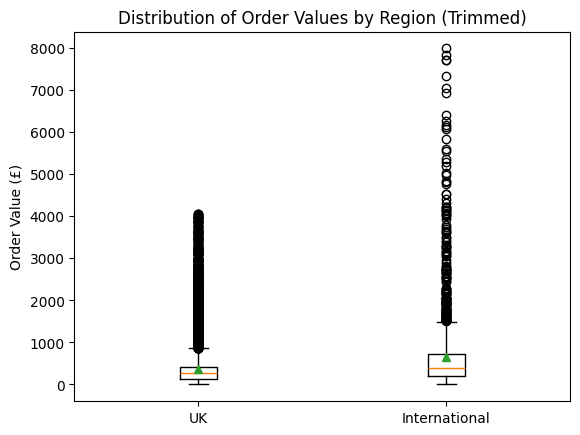

In [79]:
plt.boxplot(
    [uk_orders_trimmed, international_orders_trimmed],
    labels = ["UK", "International"],
    showmeans = True
)
plt.ylabel("Order Value (£)")
plt.title("Distribution of Order Values by Region (Trimmed)")
plt.show()

/tmp/ipykernel_435/3700011758.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


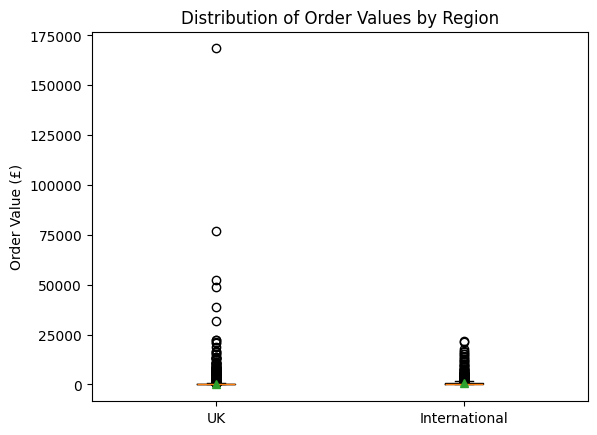

In [80]:
plt.boxplot(
    [uk_orders, international_orders],
    labels = ["UK", "International"],
    showmeans = True
)
plt.ylabel("Order Value (£)")
plt.title("Distribution of Order Values by Region")
plt.show()

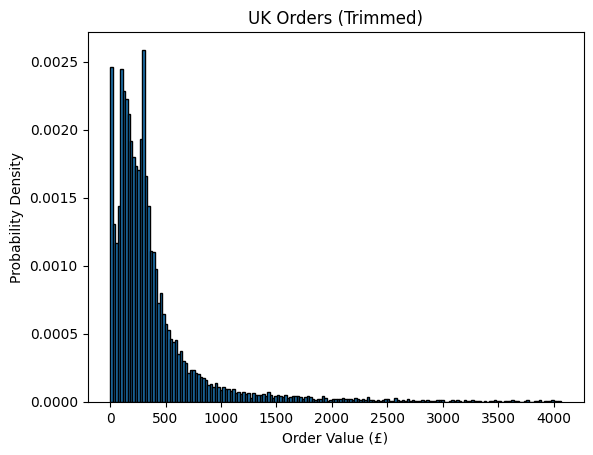

In [81]:
q25 = np.percentile(uk_orders_trimmed, 25)
q75 = np.percentile(uk_orders_trimmed, 75)
iqr = q75 - q25

bin_width = 2*iqr/(len(uk_orders_trimmed)**(1/3))

if bin_width > 0:
  bins = int(np.ceil((uk_orders_trimmed.max()-uk_orders_trimmed.min())//bin_width))
  plt.hist(uk_orders_trimmed, edgecolor = "black",linestyle="solid", bins = bins, density = True)

else:
  bins = "auto" #auto if there is a division by 0
  plt.hist(uk_orders_trimmed, edgecolor = "black",linestyle="solid", bins = bins,density = True)


plt.title("UK Orders (Trimmed)")
plt.xlabel("Order Value (£)")
plt.ylabel("Probability Density")
plt.show()

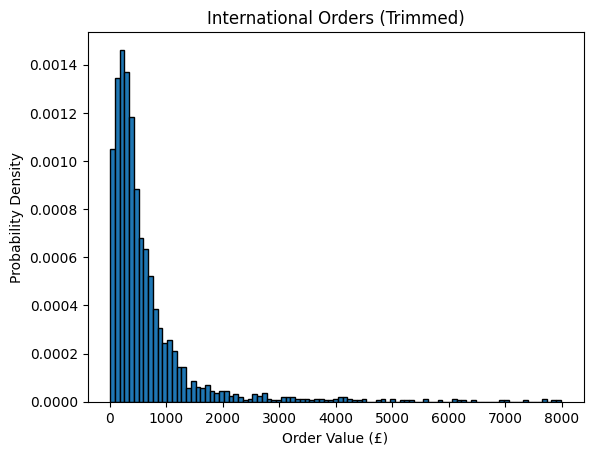

In [82]:
q25 = np.percentile(international_orders_trimmed, 25)
q75 = np.percentile(international_orders_trimmed, 75)
iqr = q75 - q25

bin_width = 2*iqr/(len(international_orders_trimmed)**(1/3))

if bin_width > 0:
  bins = int(np.ceil((international_orders_trimmed.max()-international_orders_trimmed.min())//bin_width))
  plt.hist(international_orders_trimmed, edgecolor = "black",linestyle="solid", bins = bins, density = True)

else:
  bins = "auto" #auto if there is a division by 0
  plt.hist(international_orders_trimmed, edgecolor = "black",linestyle="solid", bins = bins, density = True)


plt.title("International Orders (Trimmed)")
plt.xlabel("Order Value (£)")
plt.ylabel("Probability Density")
plt.show()

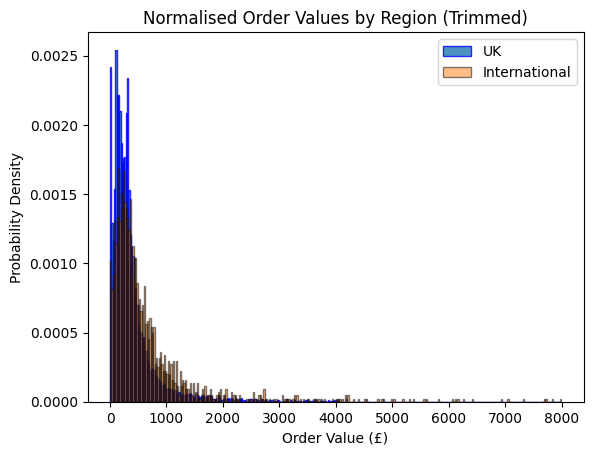

In [83]:
bins = np.histogram_bin_edges(trimmed_orderes_99["OrderValue"], bins = "fd")

plt.hist(uk_orders_trimmed, edgecolor = "blue",linestyle="solid", bins = bins, density = True, alpha = 0.8, label = "UK")
plt.hist(international_orders_trimmed, edgecolor = "black",linestyle="solid", bins = bins, density = True, alpha = 0.5,label = "International" )

plt.title("Normalised Order Values by Region (Trimmed)")
plt.xlabel("Order Value (£)")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

In [84]:
over_1000_count = regional_orders.loc[regional_orders["OrderValue"]>1000].groupby("Region")["OrderValue"].count()
over_1000_proportion = 100* (over_1000_count/regional_orders.groupby("Region").size())

In [85]:
over_1000_count

,OrderValue
Region,
International,316
UK,1352


In [86]:
over_1000_proportion

,0
Region,
International,16.364578
UK,7.567447


# Buisness Findings

**Key Findings:**

The analysis of nearly 20,000 orders from the UCI Online Retail dataset revealed substantial differences between international and UK purchase patterns.

International orders had a higher average order value, over £780, relative to the UK's average of nearly £470. This was a differnce of nearly 67%. Median values were also higher internationally compared to the UK (~£390 vs ~£270) which suggests that the difference was not inheritely driven by extreme transactions.

Welch's t-test identified a statistically significant differnce with the p-value being 0.001. After the remoal of highest 1% of orders within each region, the difference remaind statistically significant. Additionally, 16.36% of international orders exceeded £1,000 realtive to the UK's 7.57%


**Buisness Implications**

These findings suggest potential oppurtunities for retailers to investigate higher value international purchasing segments. It should be noted, however, that higher order values do no neccessitate into greater customer profitability

**Future Work**

Additional analysis should investigte:
- Customer purchasing frequency, lifetime value and customer retention
- Profit margins, delivery costs and operational expendentiture across regions
- Influence of wholesale purchasing and large transactions

An expansion of international marketing would have to be informed by profitability as well as customer level analysis rather than relying on order value alone.

# Methodology and Limitations

**Methodology**

The analysis was carried out on the UCI Online Retail dataset. It contained 541,909 transaction line records from December 2010 to December 2011.

Data preprocessing excluded cancellations, negative quantities and negative unit prices from the primary purchasing analysis. The resulting dataset contained nearly 487,000 transaction lines.

SQLite was used to aggregate transaction lines into invoice level order values and then classified into UK and international groups. Statistical analysis was performed using Python, Pandas and SciPy.

Welch's two sample t-test was also used to compare the mean order vaue, alongside 95% confidence intervals. Then a sensitivity analysis was conducted by excluding the highest 1% of order values within each region.

**Limitations**

- Customer ID - Mising CustomerID values prevented comprehensive customer level analysis.

- Independence assumption - Multiple orders may have originated from the same customer, this could potentially affect the reliability of standard errors and hypothesis tests.

- Historical data - Wholesale and individiual customers may exhibit significantly different purchasing patterns.

- Revenue vs Profitability - The dataset does not include information about product costs, delivery expense and profit margins.

- Returns - The primary analysis excludes cancellation transactions and therefore does not measure revenue after returns


As a result, findings should be interpreted as exploratory evidence of regional purchasing differences rather than casual relationships or definitive reccommendations.